PRACTICAL 5: LDA TOPIC MODELING

In [1]:
!pip install -q gensim pyLDAvis nltk scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 70.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 74.5 MB/s eta 0:00:00


In [2]:
import nltk
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [3]:
import re
import numpy as np
import matplotlib.pyplot as plt
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from gensim import corpora
from gensim.models import LdaModel
from gensim.models.coherencemodel import CoherenceModel
import pyLDAvis
import pyLDAvis.gensim_models as gensimvis

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [5]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [6]:
# --- Step 1: Load a sample corpus (20-Newsgroups) --
from sklearn.datasets import fetch_20newsgroups
categories = ['sci.space', 'rec.sport.hockey', 'talk.politics.mideast', 'comp.graphics']
newsgroups = fetch_20newsgroups(
    subset='train', categories=categories,
    remove=('headers', 'footers', 'quotes')
)
documents = newsgroups.data[:500]   # limit for speed on Colab
print(f"Loaded {len(documents)} documents")
print(documents[0][:300])

Loaded 500 documents
: 8~> I require BGI drivers for Super VGA Displays and Super XVGA Displays. Does 
: 8~> anyone know where I could obtain the relevant drivers ? (FTP sites ??)

: 	I would like to know too!

: Regards,
: Dominic

garbo.uwasa.fi (or one of its many mirrors) has a file
called "svgabg40" in the programm


In [7]:
# --- Step 2: Preprocessing (tokenization + stop word removal + lemmatization) --
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()
def preprocess(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', ' ', text)          # remove numbers/punctuation
    tokens = word_tokenize(text)
    tokens = [lemmatizer.lemmatize(t) for t in tokens
              if t not in stop_words and len(t) > 3]
    return tokens
processed_docs = [preprocess(doc) for doc in documents]
processed_docs = [doc for doc in processed_docs if len(doc) > 5]  # drop near-empty docs
print("Sample tokens:", processed_docs[0][:15])

Sample tokens: ['require', 'driver', 'super', 'display', 'super', 'xvga', 'display', 'anyone', 'know', 'could', 'obtain', 'relevant', 'driver', 'site', 'would']


In [8]:
# --- Step 3: Build dictionary and bag-of-words corpus --
dictionary = corpora.Dictionary(processed_docs)
dictionary.filter_extremes(no_below=5, no_above=0.5)   # remove rare & overly common words
bow_corpus = [dictionary.doc2bow(doc) for doc in processed_docs]

In [9]:
# --- Step 4: Train the LDA model --
NUM_TOPICS = 4
lda_model = LdaModel(
    corpus=bow_corpus,
    id2word=dictionary,
    num_topics=NUM_TOPICS,
    random_state=42,
    passes=10,
    iterations=100,
    alpha='auto',
    per_word_topics=True
)

In [10]:
# --- Step 5: Print the topics and their top words --
print("\n=== Discovered Topics ===")
for idx, topic in lda_model.print_topics(num_words=8):
    print(f"Topic {idx}: {topic}\n")


=== Discovered Topics ===
Topic 0: 0.016*"people" + 0.016*"said" + 0.016*"know" + 0.013*"armenian" + 0.011*"would" + 0.011*"like" + 0.008*"time" + 0.008*"something"

Topic 1: 0.018*"israel" + 0.017*"israeli" + 0.015*"would" + 0.009*"arab" + 0.007*"year" + 0.007*"jew" + 0.006*"armenian" + 0.006*"land"

Topic 2: 0.019*"game" + 0.012*"would" + 0.011*"team" + 0.009*"play" + 0.009*"point" + 0.009*"player" + 0.008*"graphic" + 0.007*"period"

Topic 3: 0.012*"space" + 0.012*"armenian" + 0.011*"nasa" + 0.010*"data" + 0.009*"image" + 0.008*"source" + 0.007*"system" + 0.006*"year"



In [11]:
# --- Step 6: Evaluate topic quality with Coherence Score --
coherence_model = CoherenceModel(
    model=lda_model, texts=processed_docs,
    dictionary=dictionary, coherence='c_v'
)
print(f"Coherence Score (c_v): {coherence_model.get_coherence():.4f}")

Coherence Score (c_v): 0.4115


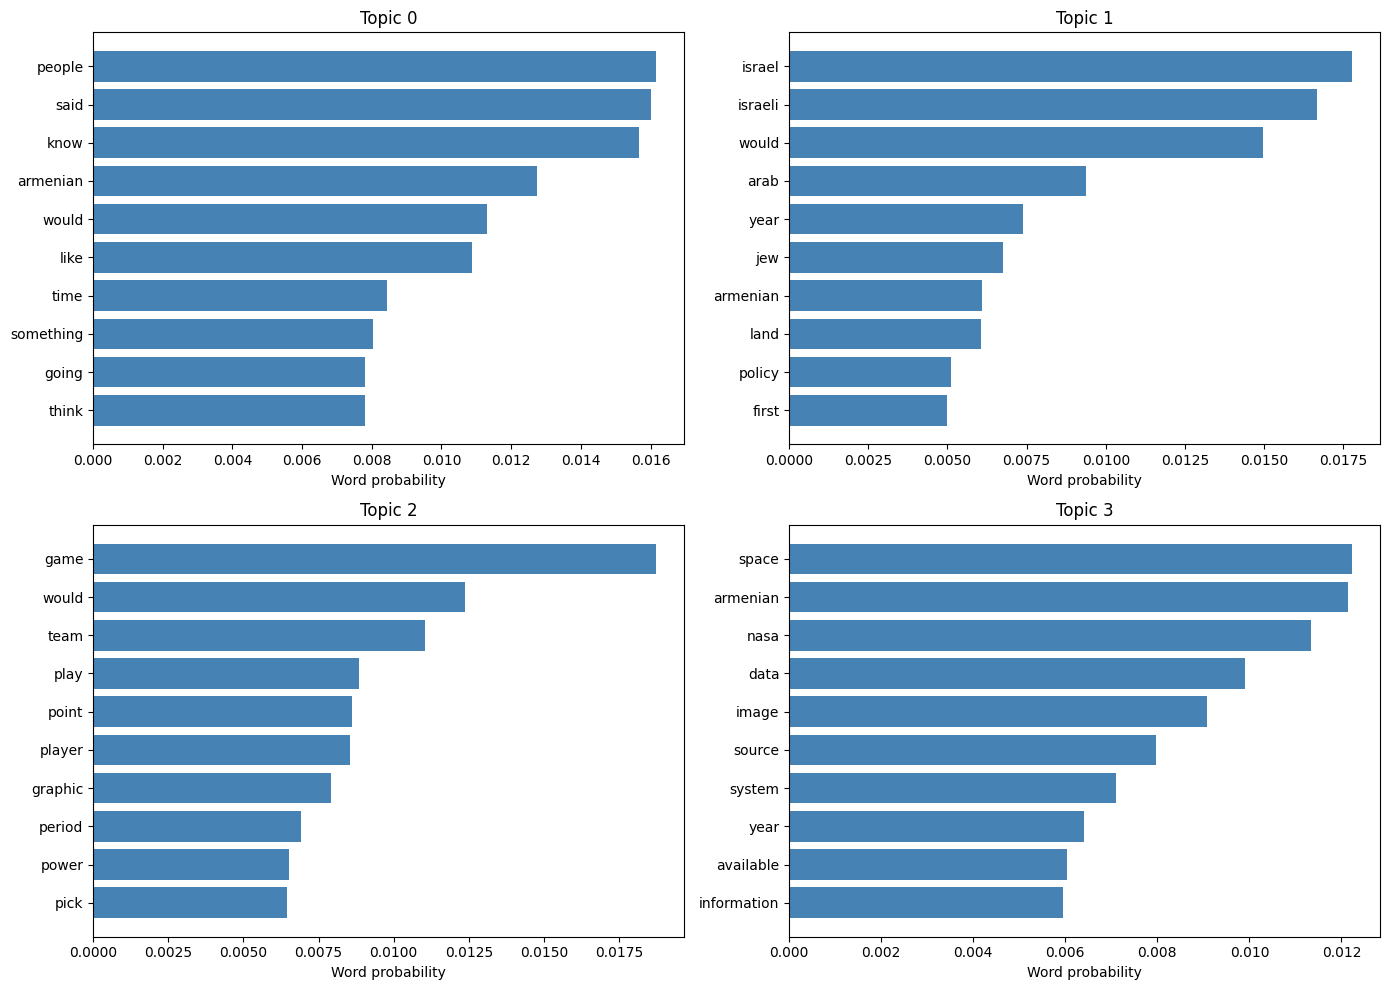

In [12]:
# --- Step 7: Visualize topics — bar charts of top words per topic --
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()
for i in range(NUM_TOPICS):
    words_probs = lda_model.show_topic(i, topn=10)
    words = [w for w, _ in words_probs][::-1]
    probs = [p for _, p in words_probs][::-1]
    axes[i].barh(words, probs, color='steelblue')
    axes[i].set_title(f"Topic {i}")
    axes[i].set_xlabel("Word probability")
plt.tight_layout()
plt.savefig('lda_topics_barchart.png', dpi=150)
plt.show()

In [13]:
# --- Step 8: Interactive visualization with pyLDAvis --
pyLDAvis.enable_notebook()
vis = gensimvis.prepare(lda_model, bow_corpus, dictionary)
pyLDAvis.save_html(vis, 'lda_visualization.html')
vis   # renders inline in Colab/Jupyter

PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
0      0.128935 -0.020354       1        1  41.626063
2     -0.153299 -0.022073       2        1  22.066956
3      0.018606 -0.078109       3        1  20.504212
1      0.005757  0.120536       4        1  15.802768, topic_info=         Term        Freq       Total Category  logprob  loglift
285      game  133.000000  133.000000  Default  30.0000  30.0000
880    israel   89.000000   89.000000  Default  29.0000  29.0000
306   israeli   85.000000   85.000000  Default  28.0000  28.0000
829      nasa   77.000000   77.000000  Default  27.0000  27.0000
1238     data   62.000000   62.000000  Default  26.0000  26.0000
...       ...         ...         ...      ...      ...      ...
283      even   18.966034  127.975861   Topic4  -5.5076  -0.0642
66       team   18.327035  103.401519   Topic4  -5.5419   0.1147
182     still   16.649052   76.469653   Topic4  -5.6379   0.3204
22       work   16.432876   67.003151   Topic4  -5.6510   0.4395
265      well   16.799798  140.002521   Topic4  -5.6289  -0.2753

[277 rows x 6 columns], token_table=      Topic      Freq      Term
term                           
1315      4  0.852059  accurate
565       1  0.946398    afraid
565       3  0.035052    afraid
1003      3  0.886023    agency
818       2  0.141692     allen
...     ...       ...       ...
23        4  0.221485     would
347       1  0.340263      year
347       2  0.176675      year
347       3  0.255197      year
347       4  0.229023      year

[609 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[1, 3, 4, 2])